# Lab 17 solution, notebook 1: roll two dice 10,000 times, and find out which user the code runs as in the hosted container

The worked answers to the two challenge tasks of `17a_meet_code_execution.ipynb`. The setup repeats what the tasks
need from the notebook, so this file runs on its own. ⚠️ Each task starts one container session on OpenAI's side
(`PRICE_CONTAINER_SESSION_USD` in `models.env`).

## Setup

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


In [2]:
import base64
from IPython.display import Image, display
from openai import OpenAI, omit

client = OpenAI(timeout=120)

OUTPUTS = ROOT / "17_Code_Execution" / "solved" / "outputs"
OUTPUTS.mkdir(exist_ok=True)

CODE_INTERPRETER = {
    "type": "code_interpreter",
    "container": {"type": "auto", "memory_limit": "1g", "network_policy": {"type": "disabled"}},
}

## Task 1: Roll two dice 10,000 times

The question asks for a count that only running code can give: no one can say in advance how many of 10,000 rolls
come up 7. We read the code and what it printed, as in Part B.

In [3]:
dice = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    input="Roll two six-sided dice 10,000 times and count how often the total is 7. Use the python tool.",
    tools=[CODE_INTERPRETER],
    include=["code_interpreter_call.outputs"],
)
dice_call = next(item for item in dice.output if item.type == "code_interpreter_call")
print(dice_call.code)
print("--- printed ---")
for output in dice_call.outputs:
    if output.type == "logs":
        print(output.logs)
print("reply:", dice.output_text)

import random
random.seed()
rolls = [random.randint(1, 6) + random.randint(1, 6) for _ in range(10_000)]
count_seven = sum(total == 7 for total in rolls)
count_seven

--- printed ---
1649
reply: In 10,000 simulated rolls, the dice totaled **7 a total of 1,649 times**.


The model wrote five lines with Python's `random` module: `random.randint(1, 6)` is one die, `rolls` is a list of 10,000 totals of two dice, and `sum(total == 7 for total in rolls)` counts the sevens (each `True` counts as 1). In our run it printed 1649, and the reply said 1,649.

The two dice show 36 equally likely pairs, and six of them add up to 7 (1+6, 2+5, 3+4, 4+3, 5+2, 6+1), so the
expected count is 10,000 × 6 / 36 ≈ 1,667. A different count on every run is what real rolls look like.

Now the chart, in the same container: `previous_response_id` continues from the dice request, so the API reuses its
container.

same container: True
import matplotlib.pyplot as plt
# rolls from prior simulation still available
counts = [sum(total == t for total in rolls) for t in range(2, 13)]
plt.figure(figsize=(8, 4.5))
plt.bar(range(2, 13), counts, color="steelblue")
plt.xticks(range(2, 13))
plt.xlabel("Dice total")
plt.ylabel("Frequency")
plt.title("Frequencies of Two-Dice Totals in 10,000 Rolls")
plt.show()



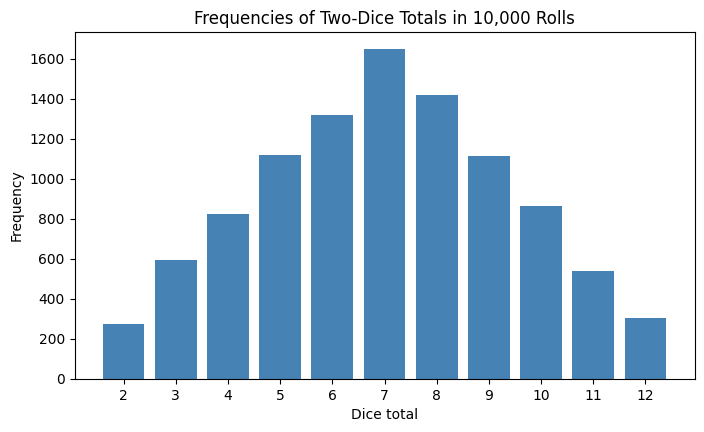

In [4]:
dice_chart = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    previous_response_id=dice.id,
    input="Draw a bar chart of how often each total from 2 to 12 came up. Show it with plt.show().",
    tools=[CODE_INTERPRETER],
    include=["code_interpreter_call.outputs"],
)
chart_calls = [item for item in dice_chart.output if item.type == "code_interpreter_call"]
print("same container:", all(c.container_id == dice_call.container_id for c in chart_calls))
print(chart_calls[-1].code)

image = next(output for c in chart_calls for output in c.outputs if output.type == "image")
png = base64.b64decode(image.url.split(",", 1)[1])
(OUTPUTS / "dice_chart.png").write_bytes(png)
display(Image(data=png, width=600))

`same container: True`, and the chart's code shows what that means: its comment says *rolls from prior simulation still available*, and it counts each total in the `rolls` list the first request made. Python's variables stay in the container between requests while it is active. The highest bar is 7, and the bars fall away on both sides towards 2 and 12.

## Task 2: Find out which user the code runs as in the hosted container

The probe from Part D, with one more line: `getpass.getuser()` returns the name of the user the code runs as. It runs
in the hosted container only, as in Part D: we ask the model to run it exactly as written and compare the code that
ran with our text.

In [5]:
PROBE = """import os, pathlib, socket
print("working folder:", pathlib.Path.cwd().name)
print("two folders up:", pathlib.Path("../..").resolve().name or "/")
print(".env there:", pathlib.Path("../../.env").exists())
print("key in environment:", "OPENAI_API_KEY" in os.environ)
try:
    socket.create_connection(("pypi.org", 443), timeout=3).close()
    print("network: reachable")
except OSError as error:
    print("network: blocked,", type(error).__name__)
"""
MY_PROBE = PROBE + 'import getpass\nprint("user:", getpass.getuser())\n'

RUN_AS_WRITTEN = ("Run the user's Python code with the python tool exactly as written, once, without changing it. "
                  "Then reply with what it printed.")
probe_response = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    instructions=RUN_AS_WRITTEN,
    input=MY_PROBE,
    tools=[CODE_INTERPRETER],
    tool_choice="required",
    include=["code_interpreter_call.outputs"],
)
probe_call = next(item for item in probe_response.output if item.type == "code_interpreter_call")
print("the code that ran is our text:", probe_call.code == MY_PROBE)
for output in probe_call.outputs:
    if output.type == "logs":
        print(output.logs)

the code that ran is our text: True
working folder: oai
two folders up: /
.env there: False
key in environment: False
network: blocked, gaierror
user: oai



`True`: the code that ran is our text. The container's answers are the same as in Part D, plus one more: the code runs as the user `oai`, a user of OpenAI's container, not as you.